# Regime classifier: which controller should each window get?

The awareness layer chooses one of three controller regimes (Live_Update 2.0 and 6.0):

| controller class | regime |
|---|---|
| ID-safe (normal, incline and weighted walking, stairs) | spline: the phase-based torque profile |
| OOD-safe (18 tasks) | Young's joint moment estimator |
| OOD-dangerous (ball toss, step-ups, tug of war, sit-to-stand) | exo off, the user acts |

Notebook 05 found the novelty scores excellent at *unfamiliar against familiar* and notebook 07 found them unable to tell
*dangerous from safe*, while a supervised read-out of the latent could (0.92). This notebook builds that supervised
classifier and asks the question notebook 07 could not: does it still keep a dangerous movement it **never saw** away from
the spline?

**Features** (no retraining; everything comes from exports and caches the earlier notebooks wrote), per window:

| set | what | source |
|---|---|---|
| rhythm | the seven spectral (rhythm) features | the window table |
| latent | the 4 x 8 posterior means of the TCN-VAE trained on ID + OOD-safe movement, 3 s + spectral input, β 128 (the best read-out in notebook 07, 0.924) | `runs_train_class/id_ood_safe` |
| novelty | LOF, Mahalanobis distance and posterior variance of the ID-trained LSTM-VAE on 3 s raw (the best unfamiliar-movement detector, notebook 05) | `runs/vae`, score cache |

**Protocol, fixed before fitting** (`_regime_classifier.py`):

| step | rule |
|---|---|
| data | in-task windows with 3 s of clean history; only the validation (4) and test (4) participants have every window exported |
| fit | on the validation participants; the feature set and model are chosen by leave-one-participant-out cross-validation within them |
| test | the four test participants, scored once; the encoder seed and the classifier seed vary together (three seeds) |
| decision | class probabilities smoothed by the 0.5 s causal median by recording, then the most probable regime |
| metrics | macro F1, each regime's recall, dangerous windows sent to the spline, safe windows switched off |
| held-out tasks | each OOD task left out of fitting in turn: where do its test windows go? |
| target ablation | the classifier is trained on the regime, the task family, the task, or dangerous-or-not (ID left to the heuristic); every target is mapped to a regime and scored the same way |
| encoder comparison | each model type's latent, under each training class, as the only input: which encoder puts the classifier in the best position? |

Results go to `results/06_*.csv`, figures to `figures/06_*.png`.

## Findings at a glance

- **The regime classifier works where the novelty scores could not.** Boosted trees on the latent, the novelty scores and
  the rhythm features (chosen by cross-validation on the validation participants) reach a test macro F1 of 0.868 ± 0.005
  (majority 0.274, rhythm features alone 0.591): 93% of ID windows get the spline, 92% of OOD-safe windows the estimator,
  79% of dangerous windows are switched off, **no dangerous window gets the spline**, and 2.8% of safe windows are switched off.
- **The nonlinear model and the extra features matter more than the encoder.** With the latent alone, a logistic regression
  reaches 0.66 to 0.69 for every encoder (section 4; the TCN-VAE trained on ID + OOD-safe is first, 0.690, by a small
  margin); adding the novelty scores and rhythm features and a boosted tree raises it to 0.868.
- **Target ablation (section 3):** predicting dangerous-or-not with ID left to a perfect heuristic gives 0.918; the
  regime directly 0.868; the task then its regime 0.857; the task family fails (0.491), because no family is mostly
  dangerous, so it never switches off.
- **A dangerous movement it never saw goes to the estimator, not the spline.** Each dangerous task left out of fitting is
  almost never given the spline (under 0.5% of windows) but only 30 to 38% switched off; the rest go to the estimator.
  Held-out step-ups are switched off in only 1 to 5% of windows: they look like stairs and curbs.
- **The cost is false shutdowns on posture tasks.** Squats, lifting and lunges are switched off in 29 to 35% of their
  windows; obstacle and dynamic walking mostly get the spline (68 to 82%).

In [1]:
import json
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

REPO = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'ml' / 'nature' / 'nature_data.py').exists())
for folder in ('ml/common', 'ml/nature', 'notebooks/nature/model_exploration/onboard'):
    if str(REPO / folder) not in sys.path:
        sys.path.insert(0, str(REPO / folder))
import nature_data as nt
import _novelty_scores as ns
import _regime_classifier as rc

ROOT = REPO / 'notebooks' / 'nature' / 'model_exploration'
DATA = REPO / 'data' / 'processed_nature' / 'ae'
CACHE = REPO / 'data' / 'cache' / 'nature' / 'novelty'
FIG_DIR, RESULTS = Path.cwd() / 'figures', Path.cwd() / 'results'
SEEDS = (0, 1, 2)
ENCODER = ROOT / 'runs_train_class' / 'id_ood_safe' / 'vae' / 'tcn_vae_raw_3s_spectral_b128_fixed_s{seed}'   # inputs raw_3s_spectral
DETECTOR = ROOT / 'runs' / 'vae' / 'lstm_vae_raw_3s_b1_fixed_s{seed}'                                      # inputs raw_3s
NOVELTY = ['LOF, raw latent', 'Mahalanobis, latent', 'posterior variance']
REGIME_C = dict(zip(rc.REGIMES, ['#287da8', '#dd791a', '#a32d2d']))     # notebook 01's controller-class colours
pd.set_option('display.width', 220)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 9})

meta = json.loads((DATA / 'meta.json').read_text())
tables = {inputs: pd.read_parquet(DATA / spec['table']) for inputs, spec in meta['inputs'].items()}
rows = {split: rc.get_split_rows(tables['raw_3s'], split) for split in ('val', 'test')}
keys = {split: r[['rec', 'end']] for split, r in rows.items()}
y = {split: r['controller_class'].astype(str).to_numpy() for split, r in rows.items()}
for split in ('val', 'test'):
    print(f"{split}: {len(y[split]):,} windows, participants {sorted(rows[split]['subject'].astype(str).unique())}; "
          + ', '.join(f'{c} {np.mean(y[split] == c):.0%}' for c in rc.REGIMES))

val: 173,590 windows, participants ['BT09', 'BT12', 'BT13', 'BT21']; ID-safe 20%, OOD-safe 67%, OOD-dangerous 13%
test: 137,955 windows, participants ['BT07', 'BT15', 'BT19', 'BT22']; ID-safe 18%, OOD-safe 70%, OOD-dangerous 12%


## 1. Features

The latent and the novelty scores of each seed's runs, aligned to the same windows; the rhythm features are the same for
every seed.

In [2]:
t0 = time.time()
features = {}
for seed in SEEDS:
    latent = rc.get_latents(Path(str(ENCODER).format(seed = seed)), tables['raw_3s_spectral'], keys)
    novelty = rc.get_novelty(Path(str(DETECTOR).format(seed = seed)), tables['raw_3s'], keys, NOVELTY, CACHE)
    rhythm = {split: rows[split][rc.RHYTHM].to_numpy(dtype = np.float64) for split in ('val', 'test')}
    features[seed] = {'rhythm': rhythm, 'latent': latent, 'novelty': novelty}
SETS = {'rhythm': ['rhythm'], 'novelty': ['novelty'], 'latent': ['latent'], 'latent + novelty': ['latent', 'novelty'],
        'latent + novelty + rhythm': ['latent', 'novelty', 'rhythm']}


def get_x(seed: int, split: str, parts: list[str]) -> np.ndarray:
    # the feature columns of one set: (N, sum of widths)
    return np.concatenate([features[seed][p][split] for p in parts], axis = 1)


print({name: get_x(0, 'val', parts).shape[1] for name, parts in SETS.items()}, f'{time.time() - t0:.0f} s')

{'rhythm': 7, 'novelty': 3, 'latent': 32, 'latent + novelty': 35, 'latent + novelty + rhythm': 42} 1 s


## 2. Baselines and classifiers

The majority regime, then a multinomial logistic regression (class-balanced, standardized features) on each feature set,
and a gradient-boosted tree on the full set. Chosen by leave-one-participant-out cross-validation on the validation
participants (macro F1); every configuration is then fitted on all four and scored once on the test participants.

In [3]:
MODELS = {'majority': lambda s: DummyClassifier(strategy = 'most_frequent'),
          'logistic': lambda s: make_pipeline(StandardScaler(), LogisticRegression(class_weight = 'balanced', max_iter = 2000)),
          'boosted trees': lambda s: HistGradientBoostingClassifier(class_weight = 'balanced', max_iter = 300, random_state = s)}
CONFIGS = [('majority', 'rhythm')] + [('logistic', name) for name in SETS] + [('boosted trees', 'latent + novelty + rhythm')]


def get_prediction(model, x_fit, y_fit, x, labels) -> np.ndarray:
    # the regime given to each window: fitted model, probabilities in REGIMES order, 0.5 s causal median, most probable
    model.fit(x_fit, y_fit)
    proba = pd.DataFrame(model.predict_proba(x), columns = model.classes_).reindex(columns = list(rc.REGIMES), fill_value = 0).to_numpy()
    return np.array(rc.REGIMES)[rc.get_smoothed(proba, labels).argmax(axis = 1)]


t0 = time.time()
subjects = rows['val']['subject'].astype(str).to_numpy()
result_rows = []
for seed in SEEDS:
    for model_name, set_name in CONFIGS:
        x_v, x_t = get_x(seed, 'val', SETS[set_name]), get_x(seed, 'test', SETS[set_name])
        cv = []
        for person in np.unique(subjects):
            fit, held = subjects != person, subjects == person
            pred = get_prediction(MODELS[model_name](seed), x_v[fit], y['val'][fit], x_v[held], rows['val'][held].reset_index(drop = True))
            cv.append(rc.get_regime_metrics(y['val'][held], pred)['macro F1'])
        pred_t = get_prediction(MODELS[model_name](seed), x_v, y['val'], x_t, rows['test'])
        result_rows.append({'model': model_name, 'features': set_name, 'seed': seed, 'CV macro F1 (validation)': np.mean(cv),
                            **{f'test {k}': v for k, v in rc.get_regime_metrics(y['test'], pred_t).items()}})
scores = pd.DataFrame(result_rows)
scores.to_csv(RESULTS / '06_regime_scores.csv', index = False)
summary = scores.groupby(['model', 'features'], sort = False).agg(['mean', 'std'])
show = pd.DataFrame({c: summary[(c, 'mean')].map('{:.3f}'.format) + ' ± ' + summary[(c, 'std')].map('{:.3f}'.format)
                     for c in scores.columns if c not in ('model', 'features', 'seed')})
display(show)
CHOSEN = summary[('CV macro F1 (validation)', 'mean')].idxmax()
print(f'chosen on validation: {CHOSEN}; {time.time() - t0:.0f} s')

CV macro F1 (validation)  test macro F1 test recall, ID-safe test recall, OOD-safe test recall, OOD-dangerous test dangerous sent to the spline (%) test safe switched off (%)
model         features                                                                                                                                                                                                
majority      rhythm                               0.267 ± 0.000  0.274 ± 0.000        0.000 ± 0.000         1.000 ± 0.000              0.000 ± 0.000                         0.000 ± 0.000              0.000 ± 0.000
logistic      rhythm                               0.587 ± 0.000  0.591 ± 0.000        0.878 ± 0.000         0.494 ± 0.000              0.849 ± 0.000                         0.000 ± 0.000             27.561 ± 0.000
              novelty                              0.657 ± 0.006  0.648 ± 0.012        0.946 ± 0.013         0.604 ± 0.037              0.725 ± 0.035                         0.000 ± 0.000             21.587 ± 3.618
              latent                               0.681 ± 0.010  0.690 ± 0.010        0.885 ± 0.027         0.663 ± 0.006              0.858 ± 0.015                         0.016 ± 0.028             14.470 ± 0.402
              latent + novelty                     0.738 ± 0.007  0.739 ± 0.002        0.940 ± 0.019         0.722 ± 0.008              0.858 ± 0.016                         0.012 ± 0.021             14.150 ± 0.506
              latent + novelty + rhythm            0.741 ± 0.007  0.741 ± 0.003        0.944 ± 0.017         0.723 ± 0.011              0.861 ± 0.014                         0.002 ± 0.003             14.052 ± 0.537
boosted trees latent + novelty + rhythm            0.863 ± 0.003  0.868 ± 0.005        0.929 ± 0.009         0.917 ± 0.009              0.794 ± 0.009                         0.000 ± 0.000              2.798 ± 0.140

chosen on validation: ('boosted trees', 'latent + novelty + rhythm'); 479 s


## 3. Target ablation: what should the classifier predict?

The chosen features and model, trained on four targets and mapped back to a regime (`_regime_classifier.TARGETS`):
the regime directly; the task family, then the regime most of that family's fitting windows have; the task, then its
regime; and dangerous-or-not on OOD windows only, with ID windows given the spline as if the upstream heuristic were
perfect. Each is scored on the test participants, and on each dangerous task left out of fitting in turn (where do its
test windows go?). Written to `results/06_regime_targets.csv`.

In [4]:
def predict_regime(model, x_fit, label_fit, x, labels, mapping) -> np.ndarray:
    # fit on one target's labels, smooth its class probabilities by recording, take the most probable label, map it to a regime
    model.fit(x_fit, label_fit)
    proba = rc.get_smoothed(model.predict_proba(x), labels)
    return np.array([mapping[c] for c in model.classes_[proba.argmax(axis = 1)]])


def run_target(seed: int, target: str, fit_mask: np.ndarray, test_mask: np.ndarray, parts: list[str], model_name: str) -> np.ndarray:
    # the regime given to the test windows in test_mask by a classifier fitted on the validation windows in fit_mask
    use = fit_mask & rc.get_fit_rows(rows['val'], target)
    mapping = rc.get_regime_map(rows['val'][use], target)
    pred = predict_regime(MODELS[model_name](seed), get_x(seed, 'val', parts)[use], rc.get_target(rows['val'], target)[use],
                          get_x(seed, 'test', parts)[test_mask], rows['test'][test_mask].reset_index(drop = True), mapping)
    if target == 'dangerous or not':                                       # the ID heuristic, taken as perfect
        pred = np.where(y['test'][test_mask] == ns.ID, ns.ID, pred)
    return pred


t0 = time.time()
model_name, set_name = CHOSEN
DANGEROUS_TASKS = sorted(rows['test'].loc[rows['test']['controller_class'] == ns.DANGEROUS, 'task'].astype(str).unique())
everything_v, everything_t = np.ones(len(y['val']), bool), np.ones(len(y['test']), bool)
target_rows = []
for seed in SEEDS:
    for target in rc.TARGETS:
        pred = run_target(seed, target, everything_v, everything_t, SETS[set_name], model_name)
        held = {}
        for task in DANGEROUS_TASKS:
            out = run_target(seed, target, rows['val']['task'].astype(str).to_numpy() != task,
                             (rows['test']['task'].astype(str) == task).to_numpy(), SETS[set_name], model_name)
            held[task] = out
        held_all = np.concatenate(list(held.values()))
        target_rows.append({'target': target, 'seed': seed, **{f'test {k}': v for k, v in rc.get_regime_metrics(y['test'], pred).items()},
                            'held-out dangerous: sent to the spline (%)': 100 * np.mean(held_all == ns.ID),
                            'held-out dangerous: switched off (%)': 100 * np.mean(held_all == ns.DANGEROUS),
                            **{f'held-out {t}: switched off (%)': 100 * np.mean(o == ns.DANGEROUS) for t, o in held.items()}})
targets = pd.DataFrame(target_rows)
targets.to_csv(RESULTS / '06_regime_targets.csv', index = False)
summary_t = targets.drop(columns = 'seed').groupby('target', sort = False).agg(['mean', 'std'])
display(pd.DataFrame({c: summary_t[(c, 'mean')].map('{:.3f}'.format) + ' ± ' + summary_t[(c, 'std')].map('{:.3f}'.format)
                      for c in targets.columns if c not in ('target', 'seed')}).T)
print(f'{model_name}, {set_name}; {time.time() - t0:.0f} s')

target,regime,family,task,dangerous or not
test macro F1,0.868 ± 0.005,0.491 ± 0.002,0.857 ± 0.007,0.918 ± 0.002
"test recall, ID-safe",0.929 ± 0.009,0.956 ± 0.007,0.900 ± 0.006,1.000 ± 0.000
"test recall, OOD-safe",0.917 ± 0.009,0.779 ± 0.002,0.922 ± 0.007,0.957 ± 0.003
"test recall, OOD-dangerous",0.794 ± 0.009,0.000 ± 0.000,0.761 ± 0.010,0.818 ± 0.005
test dangerous sent to the spline (%),0.000 ± 0.000,0.000 ± 0.000,0.219 ± 0.323,0.000 ± 0.000
test safe switched off (%),2.798 ± 0.140,0.000 ± 0.000,3.171 ± 0.167,3.401 ± 0.200
held-out dangerous: sent to the spline (%),0.004 ± 0.007,0.068 ± 0.118,0.454 ± 0.324,0.000 ± 0.000
held-out dangerous: switched off (%),36.447 ± 3.780,0.000 ± 0.000,30.238 ± 1.860,37.677 ± 2.064
held-out ball_toss: switched off (%),24.425 ± 3.517,0.000 ± 0.000,29.210 ± 5.746,32.303 ± 1.590
held-out sit_to_stand: switched off (%),47.186 ± 7.130,0.000 ± 0.000,35.063 ± 1.953,47.153 ± 3.383


boosted trees, latent + novelty + rhythm; 1781 s


## 4. Which encoder puts the classifier in the best position?

The encoder is not meant to decide the regime; its latent is meant to make the decision easy. For each model type and
training class, the cell whose latent gave the best linear read-out in notebook 07 (`results/07_train_class_probe.csv`) is
the only input to the same classifier (logistic regression, regime target): test macro F1, dangerous windows sent to the
spline, and the four dangerous tasks left out of fitting in turn. Descriptive: nothing here is chosen on the test
participants. Written to `results/06_regime_encoders.csv`.

,,,test macro F1,"test recall, OOD-dangerous",test dangerous sent to the spline (%),held-out dangerous: sent to the spline (%),held-out dangerous: switched off (%)
type,train_class,model,,,,,
TCN-VAE,ID-safe+OOD-safe,TCN-VAE · β 128 · fixed variance · 3 s + spectral,0.690,0.858,0.016,0.046,80.902
LSTM-VAE,ID-safe+OOD-safe,LSTM-VAE · β 128 · fixed variance · 3 s + spectral,0.684,0.828,0.141,1.040,77.273
plain AE,ID-safe+OOD-safe,vanilla · 3 s + spectral,0.684,0.849,0.002,0.016,81.252
Gaussian-NLL AE,ID-safe+OOD-safe,gaussian · 3 s + spectral,0.681,0.833,0.000,0.000,80.011
LSTM-VAE,OOD-safe,LSTM-VAE · β 128 · fixed variance · 3 s + spectral,0.676,0.843,0.229,0.223,80.401
plain AE,ID-safe,vanilla · 3 s + spectral · 8x4,0.674,0.855,0.223,0.480,82.530
conv VAE,ID-safe,VAE · β 1 · fixed variance · 3 s + spectral,0.671,0.857,0.000,0.000,81.701
sparse AE,ID-safe+OOD-safe,sparse · 3 s + spectral · λ 0.1,0.670,0.834,0.000,0.000,80.276
conv VAE,ID-safe+OOD-safe,VAE · β 128 · fixed variance · 3 s + spectral,0.667,0.863,0.064,0.749,80.352


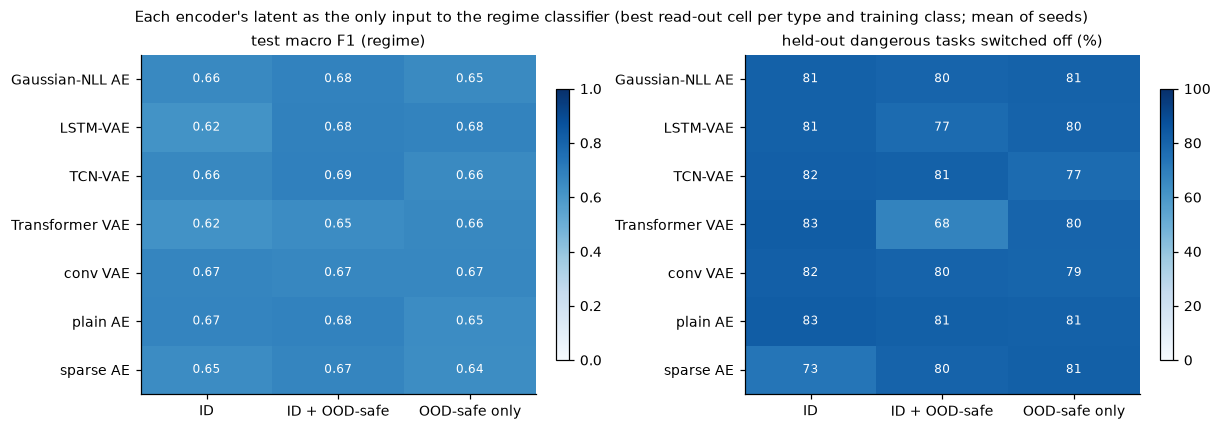

21 encoders, 517 s


In [5]:
t0 = time.time()
probe = pd.read_csv(RESULTS / '07_train_class_probe.csv')
best_cell = probe.groupby(['train_class', 'type', 'model'])['probe AUROC, dangerous vs OOD-safe'].mean().groupby(['train_class', 'type']).idxmax()
found = pd.concat([ns.discover_runs(ROOT / folder).assign(train_class = c) for c, folder in ns.TRAIN_CLASS_DIRS.items()], ignore_index = True)
encoder_rows = []
for (c, tp), key in best_cell.items():
    for seed in SEEDS:
        r = found[(found['train_class'] == c) & (found['model'] == key[2]) & (found['seed'] == seed)].iloc[0]
        z = rc.get_latents(r['run'], tables[r['inputs']], keys)
        fit_all = make_pipeline(StandardScaler(), LogisticRegression(class_weight = 'balanced', max_iter = 2000))
        pred = predict_regime(fit_all, z['val'], y['val'], z['test'], rows['test'], {k: k for k in rc.REGIMES})
        held = []
        for task in DANGEROUS_TASKS:
            keep, on = rows['val']['task'].astype(str).to_numpy() != task, (rows['test']['task'].astype(str) == task).to_numpy()
            model = make_pipeline(StandardScaler(), LogisticRegression(class_weight = 'balanced', max_iter = 2000))
            held.append(predict_regime(model, z['val'][keep], y['val'][keep], z['test'][on], rows['test'][on].reset_index(drop = True),
                                       {k: k for k in rc.REGIMES}))
        held = np.concatenate(held)
        metrics = rc.get_regime_metrics(y['test'], pred)
        encoder_rows.append({'train_class': c, 'type': tp, 'model': key[2], 'seed': seed, 'test macro F1': metrics['macro F1'],
                             'test recall, OOD-dangerous': metrics['recall, OOD-dangerous'],
                             'test dangerous sent to the spline (%)': metrics['dangerous sent to the spline (%)'],
                             'held-out dangerous: sent to the spline (%)': 100 * np.mean(held == ns.ID),
                             'held-out dangerous: switched off (%)': 100 * np.mean(held == ns.DANGEROUS)})
encoders = pd.DataFrame(encoder_rows)
encoders.to_csv(RESULTS / '06_regime_encoders.csv', index = False)
enc = encoders.groupby(['type', 'train_class', 'model'])[[c for c in encoders.columns if c.startswith(('test', 'held'))]].mean()
display(enc.sort_values('test macro F1', ascending = False).round(3))
grid = enc['test macro F1'].droplevel('model').unstack('train_class').reindex(columns = list(ns.TRAIN_CLASS_DIRS)).rename(columns = ns.TRAIN_CLASS_LABELS)
grid_h = enc['held-out dangerous: switched off (%)'].droplevel('model').unstack('train_class').reindex(columns = list(ns.TRAIN_CLASS_DIRS)).rename(columns = ns.TRAIN_CLASS_LABELS)
fig, axes = plt.subplots(1, 2, figsize = (11, 3.8), constrained_layout = True)
for ax, g, title, fmt, vmax in ((axes[0], grid, 'test macro F1 (regime)', '{:.2f}', 1.0), (axes[1], grid_h, 'held-out dangerous tasks switched off (%)', '{:.0f}', 100)):
    im = ax.imshow(g.to_numpy(dtype = float), cmap = 'Blues', vmin = 0, vmax = vmax, aspect = 'auto')
    for i in range(g.shape[0]):
        for k in range(g.shape[1]):
            v = g.iat[i, k]
            ax.text(k, i, fmt.format(v), ha = 'center', va = 'center', fontsize = 8, color = 'white' if v > .6 * vmax else '#222')
    ax.set_xticks(range(g.shape[1]), g.columns); ax.set_yticks(range(g.shape[0]), g.index); ax.set_title(title, fontsize = 9.5)
    fig.colorbar(im, ax = ax, shrink = .8)
fig.suptitle('Each encoder\'s latent as the only input to the regime classifier (best read-out cell per type and training class; mean of seeds)', fontsize = 10)
fig.savefig(FIG_DIR / '06_regime_encoders.png', dpi = 160, bbox_inches = 'tight')
plt.show()
print(f'{len(best_cell)} encoders, {time.time() - t0:.0f} s')

## 5. Where each regime's windows go

For the chosen configuration, the share of each true regime's test windows given each regime (mean over seeds), and per
task: the share of each task's windows given each regime.

given,ID-safe,OOD-safe,OOD-dangerous
true,,,
ID-safe,92.9,7.1,0.0
OOD-safe,4.8,91.7,3.5
OOD-dangerous,0.0,20.6,79.4


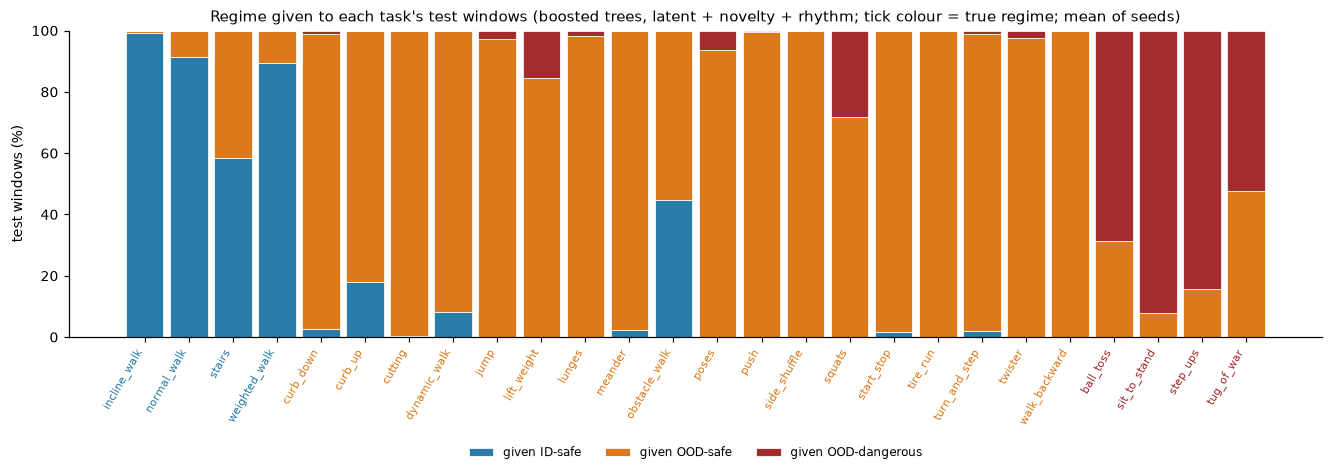

In [6]:
model_name, set_name = CHOSEN
conf, per_task = [], []
for seed in SEEDS:
    pred = get_prediction(MODELS[model_name](seed), get_x(seed, 'val', SETS[set_name]), y['val'], get_x(seed, 'test', SETS[set_name]), rows['test'])
    conf.append(rc.get_confusion(y['test'], pred))
    per_task.append(pd.crosstab(rows['test']['task'].astype(str), pred, normalize = 'index').reindex(columns = list(rc.REGIMES), fill_value = 0) * 100)
conf = sum(conf) / len(conf)
per_task = sum(per_task) / len(per_task)
display(conf.round(1))
classes = rows['test'].drop_duplicates('task').set_index(rows['test'].drop_duplicates('task')['task'].astype(str))['controller_class'].astype(str)
order = [t for c in rc.REGIMES for t in sorted(classes[classes == c].index)]
per_task = per_task.reindex(order)
per_task.assign(true = classes.reindex(order)).to_csv(RESULTS / '06_regime_per_task.csv')
fig, ax = plt.subplots(figsize = (12, 4.2), constrained_layout = True)
bottom = np.zeros(len(order))
for r in rc.REGIMES:
    ax.bar(range(len(order)), per_task[r], bottom = bottom, color = REGIME_C[r], width = .85, label = f'given {r}', edgecolor = 'white', linewidth = .5)
    bottom += per_task[r].to_numpy()
ax.set_xticks(range(len(order)), [f'{t}' for t in order], rotation = 60, ha = 'right', fontsize = 7.5)
for k, t in enumerate(order):
    ax.get_xticklabels()[k].set_color(REGIME_C[classes[t]])
ax.set(ylabel = 'test windows (%)', ylim = (0, 100))
ax.legend(loc = 'upper center', bbox_to_anchor = (.5, -.32), ncol = 3, frameon = False, fontsize = 8)
ax.set_title(f'Regime given to each task\'s test windows ({model_name}, {set_name}; tick colour = true regime; mean of seeds)', fontsize = 9.5)
fig.savefig(FIG_DIR / '06_regime_per_task.png', dpi = 160, bbox_inches = 'tight')
plt.show()

## 6. A movement it never saw

The real test. Each of the 22 OOD tasks is left out of fitting in turn (its validation windows removed), the chosen
configuration is fitted on the rest, and the left-out task's **test** windows are classified. For a held-out dangerous
task the worst outcome is the spline; for a held-out safe task it is being switched off. Written to
`results/06_regime_held_out_tasks.csv`.

given ID-safe (%)  given OOD-safe (%)  given OOD-dangerous (%)
true regime   task                                                                         
OOD-safe      curb_down                    4.5                94.6                      1.0
              curb_up                     21.6                78.4                      0.0
              cutting                      0.3                99.6                      0.1
              dynamic_walk                67.5                32.5                      0.0
              jump                         0.0                91.5                      8.5
              lift_weight                  0.0                68.9                     31.1
              lunges                       0.0                70.9                     29.1
              meander                      3.3                96.1                      0.6
              obstacle_walk               82.2                17.8                      0.0
              poses                        0.0                83.4                     16.5
              push                         0.1                99.1                      0.8
              side_shuffle                 0.0                99.7                      0.3
              squats                       0.0                65.1                     34.9
              start_stop                   3.1                96.9                      0.0
              tire_run                     0.0                99.8                      0.2
              turn_and_step                3.0                95.1                      2.0
              twister                      0.0                96.5                      3.5
              walk_backward                2.6                97.4                      0.0
OOD-dangerous ball_toss                    0.0                75.6                     24.4
              sit_to_stand                 0.0                52.8                     47.2
              step_ups                     0.0                98.8                      1.2
              tug_of_war                   0.0                68.7                     31.3

1260 s


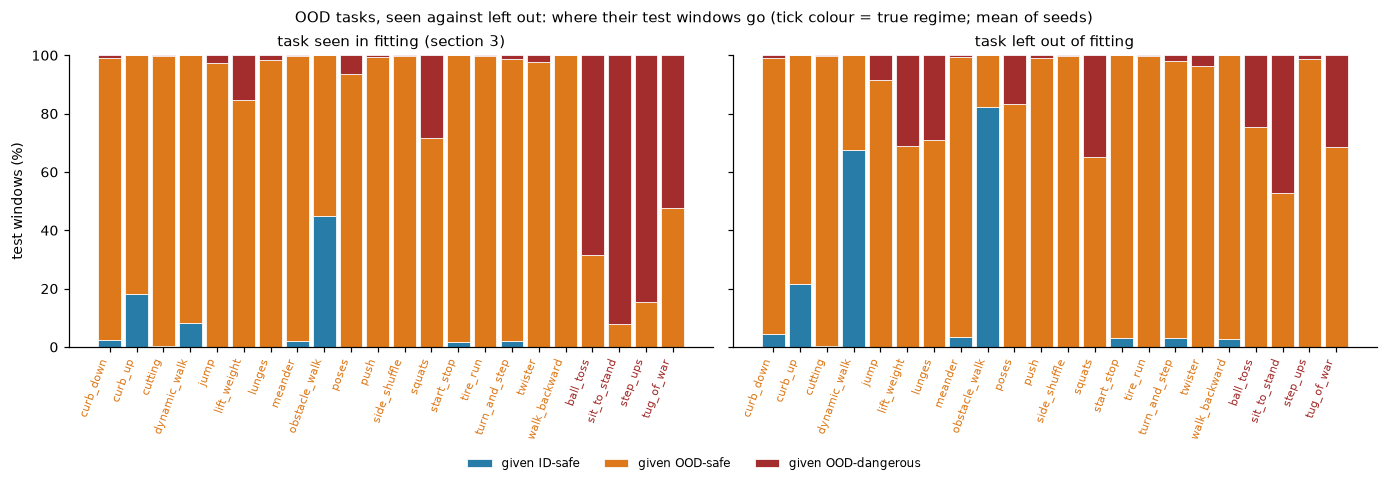

In [7]:
t0 = time.time()
ood_tasks = [t for t in order if classes[t] != ns.ID]
held_rows = []
for seed in SEEDS:
    x_v, x_t = get_x(seed, 'val', SETS[set_name]), get_x(seed, 'test', SETS[set_name])
    for task in ood_tasks:
        fit = rows['val']['task'].astype(str).to_numpy() != task
        on = (rows['test']['task'].astype(str) == task).to_numpy()
        pred = get_prediction(MODELS[model_name](seed), x_v[fit], y['val'][fit], x_t[on], rows['test'][on].reset_index(drop = True))
        held_rows.append({'seed': seed, 'task': task, 'true regime': classes[task], **{f'given {r} (%)': 100 * np.mean(pred == r) for r in rc.REGIMES}})
held = pd.DataFrame(held_rows)
held.to_csv(RESULTS / '06_regime_held_out_tasks.csv', index = False)
held_mean = held.groupby(['true regime', 'task'], sort = False)[[f'given {r} (%)' for r in rc.REGIMES]].mean()
display(held_mean.round(1))
seen = per_task.loc[ood_tasks]
cols = [f'given {r} (%)' for r in rc.REGIMES]
print(f'{time.time() - t0:.0f} s')
fig, axes = plt.subplots(1, 2, figsize = (12.5, 4), sharey = True, constrained_layout = True)
for ax, (title, frame) in zip(axes, (('task seen in fitting (section 3)', seen.set_axis(cols, axis = 1)),
                                     ('task left out of fitting', held_mean.droplevel(0).reindex(ood_tasks)))):
    bottom = np.zeros(len(ood_tasks))
    for r, c in zip(rc.REGIMES, cols):
        ax.bar(range(len(ood_tasks)), frame[c], bottom = bottom, color = REGIME_C[r], width = .85, label = f'given {r}', edgecolor = 'white', linewidth = .5)
        bottom += frame[c].to_numpy()
    ax.set_xticks(range(len(ood_tasks)), ood_tasks, rotation = 70, ha = 'right', fontsize = 7)
    for k, t in enumerate(ood_tasks):
        ax.get_xticklabels()[k].set_color(REGIME_C[classes[t]])
    ax.set_title(title, fontsize = 9.5)
axes[0].set_ylabel('test windows (%)')
fig.legend(*axes[0].get_legend_handles_labels(), loc = 'upper center', bbox_to_anchor = (.5, 0), ncol = 3, frameon = False, fontsize = 8)
fig.suptitle('OOD tasks, seen against left out: where their test windows go (tick colour = true regime; mean of seeds)', fontsize = 10)
fig.savefig(FIG_DIR / '06_regime_held_out_tasks.png', dpi = 160, bbox_inches = 'tight')
plt.show()

## 7. What this shows

- **For the pipeline:** a supervised classifier on the encoder's latent plus novelty scores is the right shape for the
  regime decision: it never sends dangerous movement to the spline, even movement it never saw, which is the failure that
  matters most. Its weakness is the other direction: unseen dangerous movement mostly gets the moment estimator instead
  of being switched off.
- **The encoder is not the bottleneck.** Every encoder's latent supports a similar linear classifier (0.64 to 0.69); the
  gains come from combining the latent with the ID-trained novelty scores and the rhythm features in a nonlinear model.
- **The target should be the regime or dangerous-or-not, not the family:** families mix regimes (stairs with step-ups,
  squats with sit-to-stand), which is the same overlap that defeated the novelty scores in notebook 07.
- **Next:** fit on the training participants as well (encode their windows; only 4 people fit the classifier here), add
  the per-movement view (how fast a regime switch happens, notebook 05 section 8), and decide with the estimator-error
  labels (data exploration notebook 04) whether step-ups belong in the dangerous class at all.
- **Limits:** 4 fitting and 4 test participants; one encoder seed per classifier seed; the held-out-task test covers the
  22 OOD tasks of this dataset, not genuinely new movements.